## Decomposing spectra with MFICA

This tutorial aims to show you how to use MFICA to decompose galaxy and quasar spectra, making plots to validate spectrum decomposition, and extracting useful properties such as the star-formation histories (SFHs) of the decomposed galaxy spectra.

## Using MFICA with galaxy spectra

### Step 0: Import basic packages

First, let us import some useful basic packages, including the MFICA package.

In [1]:
from mfica_decomp import mfica # Import the MFICA package
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import units as u
from dust_extinction.parameter_averages import O94, CCM89
from copy import deepcopy

### Step 1: Loading spectra

The MFICA class takes as input only three arrays:

1. The wavelengths in Angstrom.
2. The fluxes at each wavelength.
3. The errors for each flux.

For the time being, MFICA assumes that these spectra have been correct for MW dust extinction, shifted to rest-frame, and spliced to a rest-frame coverage of 3300-5200 Angstroms. These will be implemented in due time to handle any generic spectrum.

For this tutorial, we will make use of random SDSS DR7 spectra. Below is a helper function that allows you to load a spectrum given its URL on the SDSS CAS server. The helper function also removes MW extinction, shifts the spectra to rest-frame, and limits it to a wavelength coverage of 3300-5200 angstroms. Just run the cell below as is.

In [2]:
# Get header and data from fits file
def load_spec(file):
    
    hdul = fits.open(file)
    header = hdul[0].header
    data = hdul[0].data
    return header, data

# Extract important information from it
def extract_spec(header, data):
    
    flux = np.array(data[0,:])
    err = np.array(data[1,:])
    c0 = header['COEFF0']
    c1 = header['COEFF1']
    naxis1 = header['NAXIS1']
    wave_log = c0 + (c1*np.arange(naxis1)) # log wavelengths
    wavelength = 10 ** wave_log
    Ebv = header['SFD_EBV']
    z = header['Z']
    sn_g = header['SN_G']
    return wavelength, wave_log, flux, err, Ebv, z, sn_g


# THIS SECTION NEEDS TO BE IMPROVED
def mask_spectra(wavelength, flux, err, w):
    # NOTE: Flux and wavelegnth must be in observed frame.
    skylines = [[5574,5590],[4276,4282],[6297,6305],[6364,6368]]
    # The inner list are ranges of wavelengths that need to be masked.
    upper = [x[1] for x in skylines]
    lower = [x[0] for x in skylines]
    # Mask between upper and lower
    mask = []
    for i in range(len(upper)):
        index = np.where((wavelength < float(upper[i])) & (wavelength >= float(lower[i])))[0] # From Hin's code
        mask.extend(index)
     
    #for i in range(len(mask)):
    #    flux[mask[i]] = flux[mask[i]-1]
    
    err[mask] = np.nan
    w[mask] = np.nan
    return flux, err, w

def mask_extra(wavelength, flux, err, w):
    # Mask the specific lines from Prof. Hewett's mail
    central_wl = [5578.5, 5893.9, 6301.7]
    width = [12.0, 16.0, 10.0]
    window = [x / 2.0 for x in width]
    upper = [x+y for x, y in zip(central_wl, window)]
    lower = [x-y for x, y in zip(central_wl, window)]
    
    mask = []
    for i in range(len(upper)):
        index = np.where((wavelength < upper[i]) & (wavelength >= lower[i]))[0] # From Hin's code
        mask.extend(index)

    #for i in range(len(mask)):
        #flux[mask[i]] = flux[mask[i]-1]

    err[mask] = np.nan 
    w[mask] = np.nan
    
    return flux, err, w

# def function for dust extinction correction.
def ext_corr(wavelength, flux, err, Ebv):
    new_er = err * (1e-17)*u.erg/((u.cm)**2)/u.s/u.AA
    new_wl = wavelength * u.AA
    new_fl = flux * (1e-17)*u.erg/((u.cm)**2)/u.s/u.AA
    ext = O94(Rv=3.1) # Initialise the O'Donnell 1994 MW dust extinction model
    unred_flux = new_fl / ext.extinguish(new_wl, Ebv=Ebv)
    unred_err = new_er / ext.extinguish(new_wl, Ebv=Ebv)
    # reduce mem load and del variables
    del ext, new_wl, new_fl, new_er
    return wavelength, unred_flux, unred_err


# def function for redshift correction.
def rz_corr(wavelength, flux, err, z):
    log_wave_rest = np.array(wavelength - (np.round((np.log10(1+z)*1e4))/1e4))
    wavelength, flux, err = np.array(wavelength), np.array(flux), np.array(err)
    flux_rest = flux * ((10**(wavelength))/(10**(log_wave_rest)))
    #err_rest = [err[i] * ((10**(wavelength[i]))/(10**(log_wave_rest[i]))) if err[i].value != 9.9e9 else err[i] for i in range(len(err))]
    err_rest = err * ((10**(wavelength))/(10**(log_wave_rest)))
    wave_rest = 10**log_wave_rest
    return wave_rest, flux_rest, err_rest

# def function to normalise by median of flux
def md_norm(flux):
    median = np.median(flux)
    flux1 = flux / median
    #print(median)
    return flux1, median

# def function to normalise by weighted flux
def mn_norm(wl, flux, err):
    #cnd = np.where((wl > 4100) & (wl < 4200))[0]
    #mean = np.mean(flux[189:1701]) # Use only the central 80% to calculate the mean (Paul follows this)
    mean = np.mean(flux)
    flux2 = flux / mean
    err2 = err / mean
    return flux2, err2, mean

# THIS SECTION NEEDS TO BE CHECKED AND IMPROVED!!
def compress(wavelength, flux, err, w):
    
    index = [3.300654e+03-1e-2 <= item <= 5.200e+03+1e-2 for item in wavelength]
    wavelength = wavelength[index]
    flux = flux[index]
    err = err[index]
    w = w[index]
    return wavelength, flux, err, w

#===================== Compiled function =========================#

def load_data(data_loc):
    
    header, data = load_spec(data_loc)
    wavelength, wave_log, flux, err, Ebv, z, sn_g = extract_spec(header, data)
    w = np.ones(len(err))
    flux, err, w = mask_spectra(wavelength, flux, err, w)
    flux, err, w = mask_extra(wavelength, flux, err, w)
    wavelength, flux, err = ext_corr(wavelength, flux, err, Ebv) # O'Donnell et al. 1994 MW dust extinction
    wavelength, flux, err = rz_corr(wave_log, flux, err, z) # Use given redshifts instead
    wavelength, flux, err, w = compress(wavelength, flux, err, w)
    flux, err, mean = mn_norm(wavelength, flux, err) 
    #mean = 1
    
    flux_nonan = deepcopy(flux)
    flux_nonan[np.argwhere(np.isnan(flux))] = 0.0e0
    err_nonan = deepcopy(err)
    err_const = deepcopy(err)
    index = np.where(err != np.nan)[0]
    err_const[index] = 1.0
    
    err_nonan[np.argwhere(np.isnan(err))] = 9.9e9
    err_const[np.argwhere(np.isnan(err))] = 9.9e9
    err_nonan[np.where([x==0 for x in err_nonan])[0]] = 9.9e9 # Treat any point with error=0 as a bad point.
    
    return wavelength, flux_nonan, err_nonan, z

The function "load_data()" returns the wavelength, flux, error and redshfit for a spectrum, given its URL. We will use this now to load and plot a random SDSS spectrum.

Text(0, 0.5, 'Normalised flux')

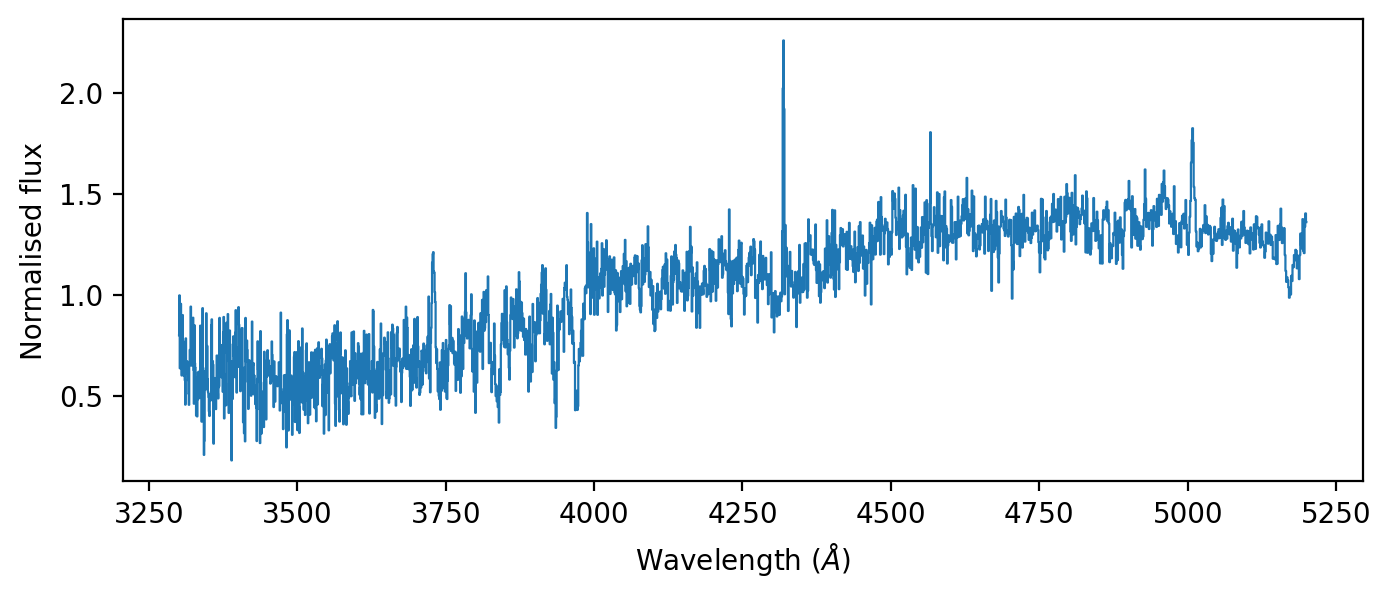

In [3]:
wl, fl, err, _ = load_data("http://www.sdss.jhu.edu/skypca/spSpec/1636/spSpec-54481-1636-622_skysub.fit")

# Plot the figure
plt.figure(figsize=(8,3), dpi=200)
plt.plot(wl, fl, lw=0.8, drawstyle='steps-mid')
plt.xlabel("Wavelength ($\AA$)")
plt.ylabel("Normalised flux")

### Step 2: Fit a galaxy spectrum with MFICA

Now we can try and fit this galaxy spectrum with MFICA. Before this, let's print out a description of the MFICA class.

In [4]:
mfica?

Init signature: mfica(wl, flux, err, gal=True, qso=True, interpolate=False)
Docstring:      <no docstring>
Init docstring:
Initialisation of MFICA object class for decomposition of spectra.
Must provide wavelength, flux and error from spectra.
Need to assume that raw spectra and redshifts are given

Parameters
----------
wl : array
    Wavelength array or list.
flux : array
    Array or list with flux values at each wavelength bin.
err : array
    Array or list with errors on individual flux values.
gal : bool, optional
    Condition to set use of galaxy components. The default is True.
qso : bool, optional
    Condition to set use of quasar components. The default is True.
interpolate: bool, optional
    Condition to determine if need interpolation of spectra. The default is False.

Raises
------
Exception
    Exception is raised if both components are set to False.

Returns
-------
None.
File:           ~/Desktop/PhD Work/MFICA/MFICA python wrapper/mfica_decomp.py
Type:           typ

The MFICA class requires three compulsory inputs - the wavelength, flux and error - and a few optional arguments. By default MFICA uses both a set of galaxy and quasar components to fit quasar. If you want to use only the galaxy components, you can use set the optional argument "qso=False". Alternatively, if you want to use only quasar components, set "gal=True".\
Now, let us initialise the MFICA class.

In [5]:
obj = mfica(wl, fl, err)

Now we can fit the galaxy spectrum.

In [6]:
obj.fit_comps() # Fit the components
obj.__dict__

{'wl': array([3300.65399529, 3301.41408646, 3302.17435267, ..., 5197.56584658,
        5198.76276814, 5199.95996534]),
 'flux': array([0.79876629, 0.99622972, 0.63523354, ..., 1.33672587, 1.40173696,
        1.35883254]),
 'err': array([0.14587695, 0.15103874, 0.14773293, ..., 0.05534595, 0.05538438,
        0.0628939 ]),
 'gspec': array([[ 0.4126097 ,  0.846773  ,  2.6271551 , ...,  1.6520004 ,
          1.2547136 ,  0.13689189],
        [ 0.41018626,  0.78155401,  2.6808221 , ...,  0.19994206,
          1.3181776 ,  0.30480361],
        [ 0.3990548 ,  0.79565496,  2.6379734 , ...,  0.27869221,
          0.95895743,  0.10187813],
        ...,
        [ 1.138871  ,  0.41075512,  0.74461092, ...,  0.27368336,
          0.12345852, -0.20918153],
        [ 1.1503634 ,  0.43339072,  0.99971387, ...,  0.11088193,
          0.0692358 , -0.02317864],
        [ 1.1560143 ,  0.48997758,  1.026825  , ...,  0.11102292,
          0.09881108,  0.18854586]]),
 'qspec': array([[ 1.1604215e+01,  9.184

The dictionary above gives a set of important quantitities returned by the MFICA fitting for the single object. These include the component fractions (labelled here w1-w3), covariance matrices and the best fit MFICA models. After fitting, the best fit models have been determined. These can be accessed by simply calling the relevant attribute of the MFICA object. For example:

In [7]:
print(obj.model_gal) # The reconstructed galaxy spectrum
print(obj.wl) # The original wavelength array provided to MFICA

[0.59814448 0.58475507 0.57721384 ... 1.21006989 1.22832662 1.24084781]
[3300.65399529 3301.41408646 3302.17435267 ... 5197.56584658 5198.76276814
 5199.95996534]


These attributes can be used to plot the best fitting model and the spectrum. While this can be done manually, the ".plot_model()" method provides a convenient means of doing this.

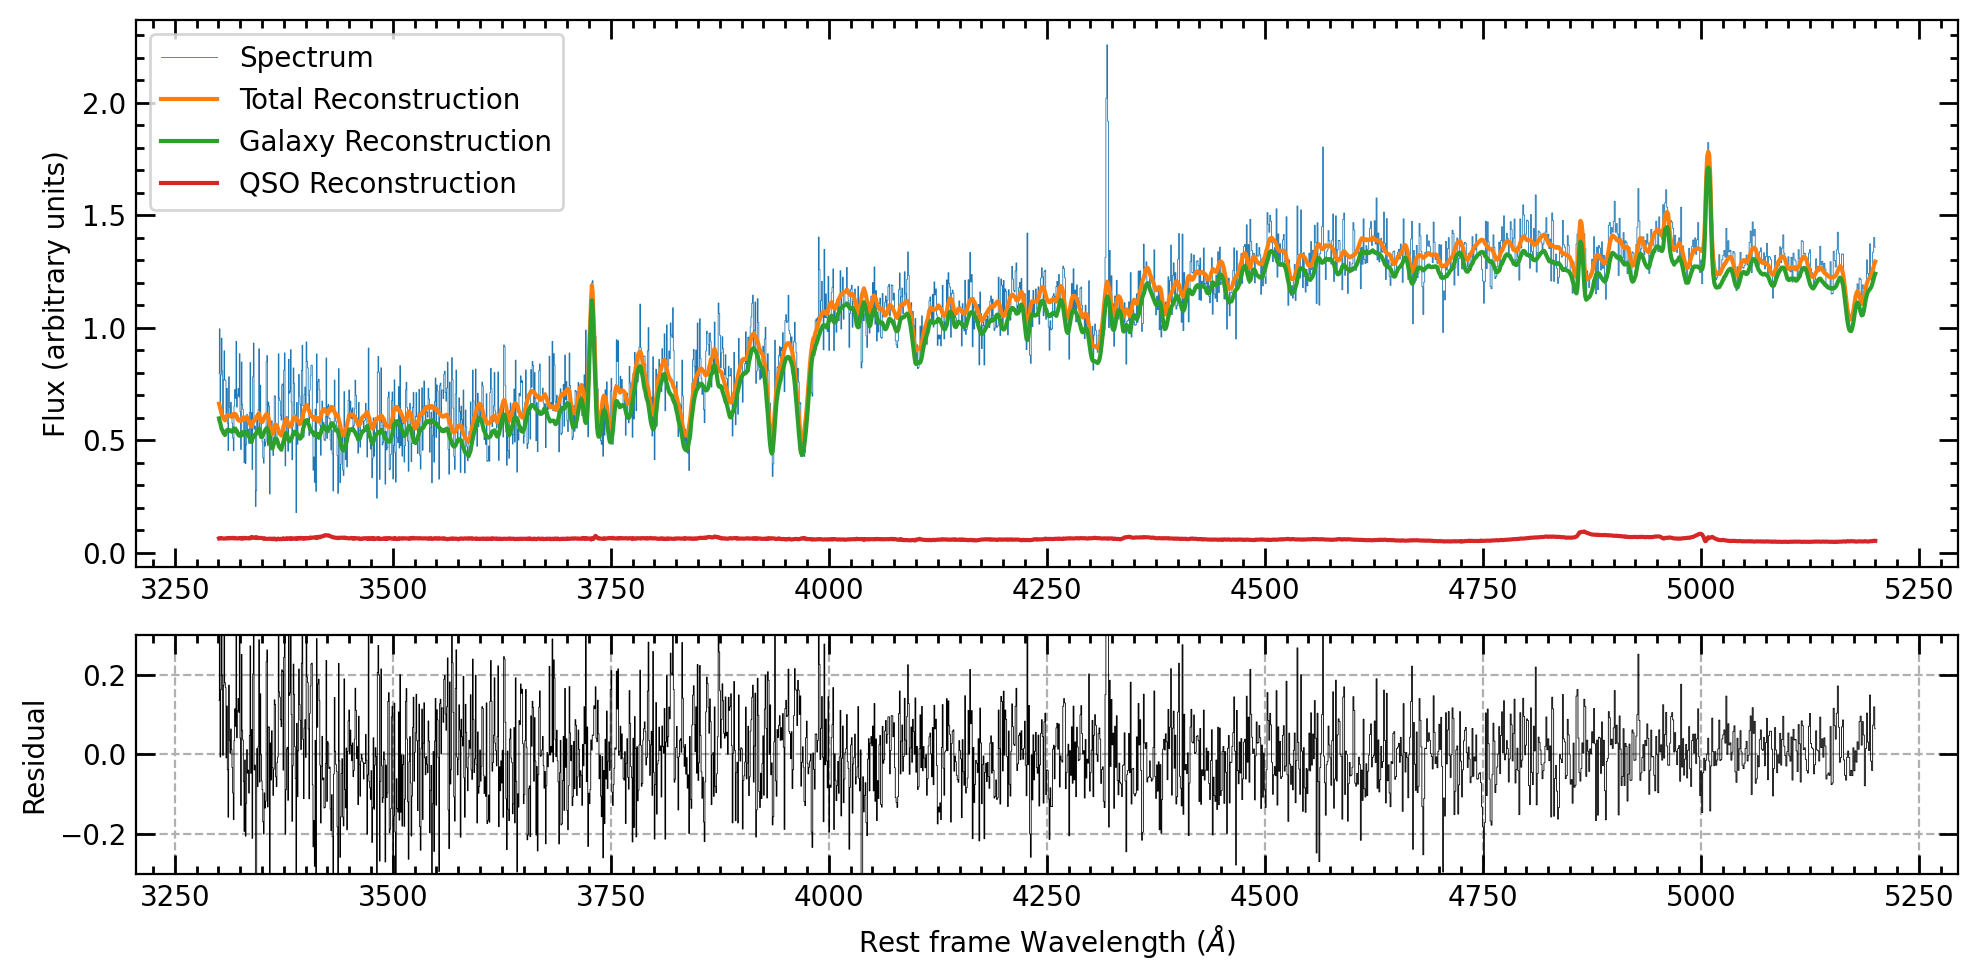

In [8]:
obj.plot_model()

As you can see in the list of parameters shown before, the component fractions (w1-w3), their errors and covariance matrices haven't been determined till now. To do this, we can use the ".get_comp_frac()" function.

In [9]:
obj.get_comp_frac()
print(obj.w1)

0.8137190029977874


To visualise these component fractions, and obtain information on the recent SFH of this galaxy, we plot its component fractions - f_AF (w2) and f_K (w1) - and characterise its current stellar populations. 

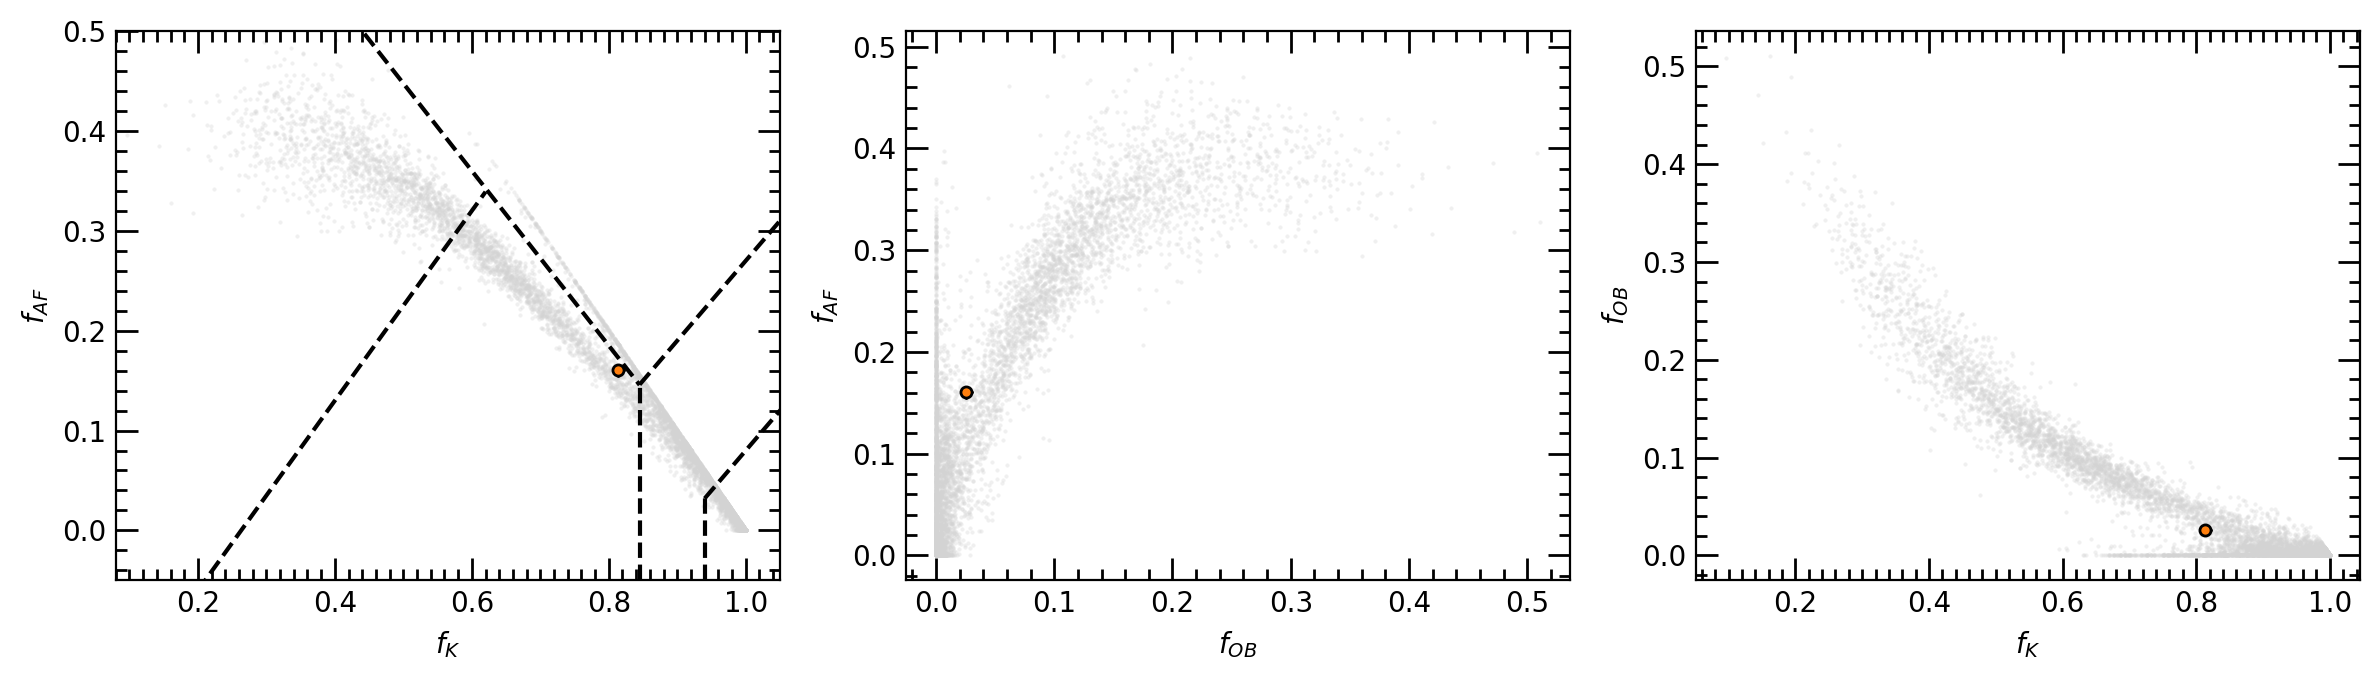

In [10]:
obj.plot_comp_frac()

For more information on how to read these plots, see Krishna et al. (2025).\
From this plot, we can infer that this galaxy is a star-forming galaxy.\
If you are simply interested in obtaining the galaxy type, you can use the ".galaxy_type()" method.

In [11]:
obj.galaxy_type()

{'SB': 0.0, 'SF': 0.9993, 'PSB': 0.0007, 'GV': 0.0, 'Red': 0.0}

This method returns the probability of a galaxy being of certain SFH type. This probability is calculated by re-sampling component fractions 10,000 times using the covariance matrix, and classifying the galaxy (using the boundaries shown above) each of the 10,000 times.

## Using MFICA for quasar spectra.

We can repeat the decomposition in exactly the same way with quasar spectra. In fact, this code was designed primarily to infer the host galaxy star-formation histories of quasars.

First, load a random SDSS quasar spectrum.

Text(0, 0.5, 'Normalised flux')

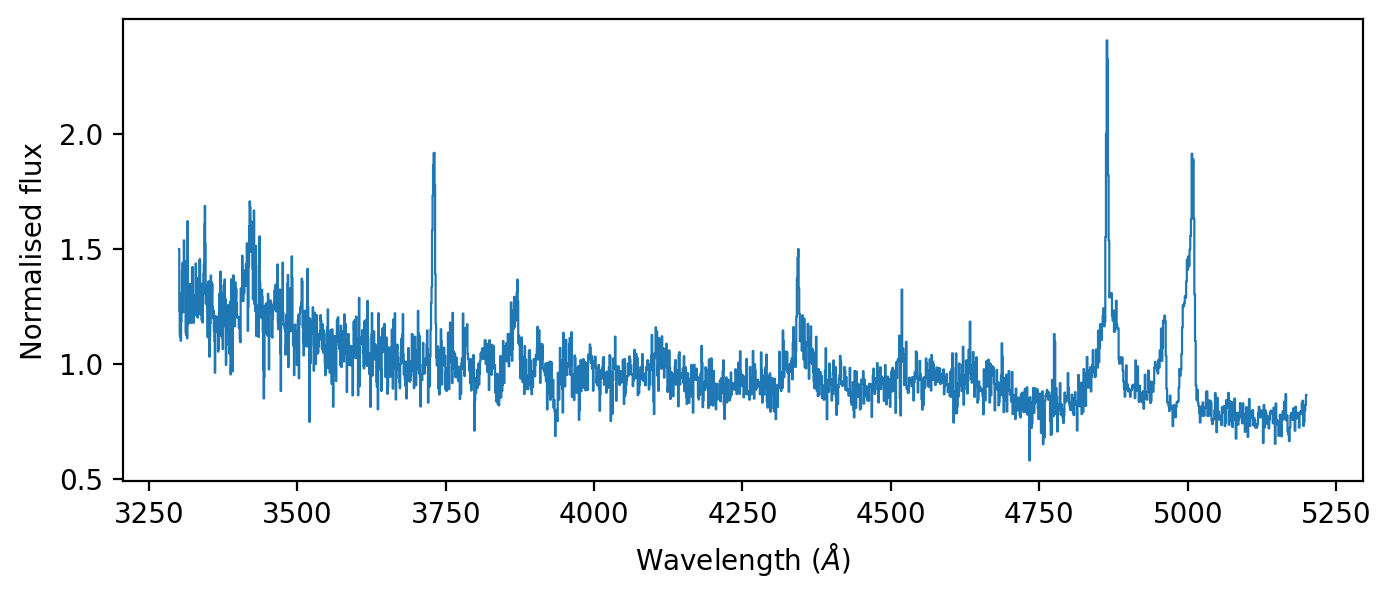

In [34]:
wl, fl, err, _ = load_data('http://www.sdss.jhu.edu/skypca/spSpec/0392/spSpec-51793-0392-496_skysub.fit')

# Plot the figure
plt.figure(figsize=(8,3), dpi=200)
plt.plot(wl, fl, lw=0.8, drawstyle='steps-mid')
plt.xlabel("Wavelength ($\AA$)")
plt.ylabel("Normalised flux")

Next, we fit the components and visualise the reconstructed host galaxy and the reconstructed quasar.

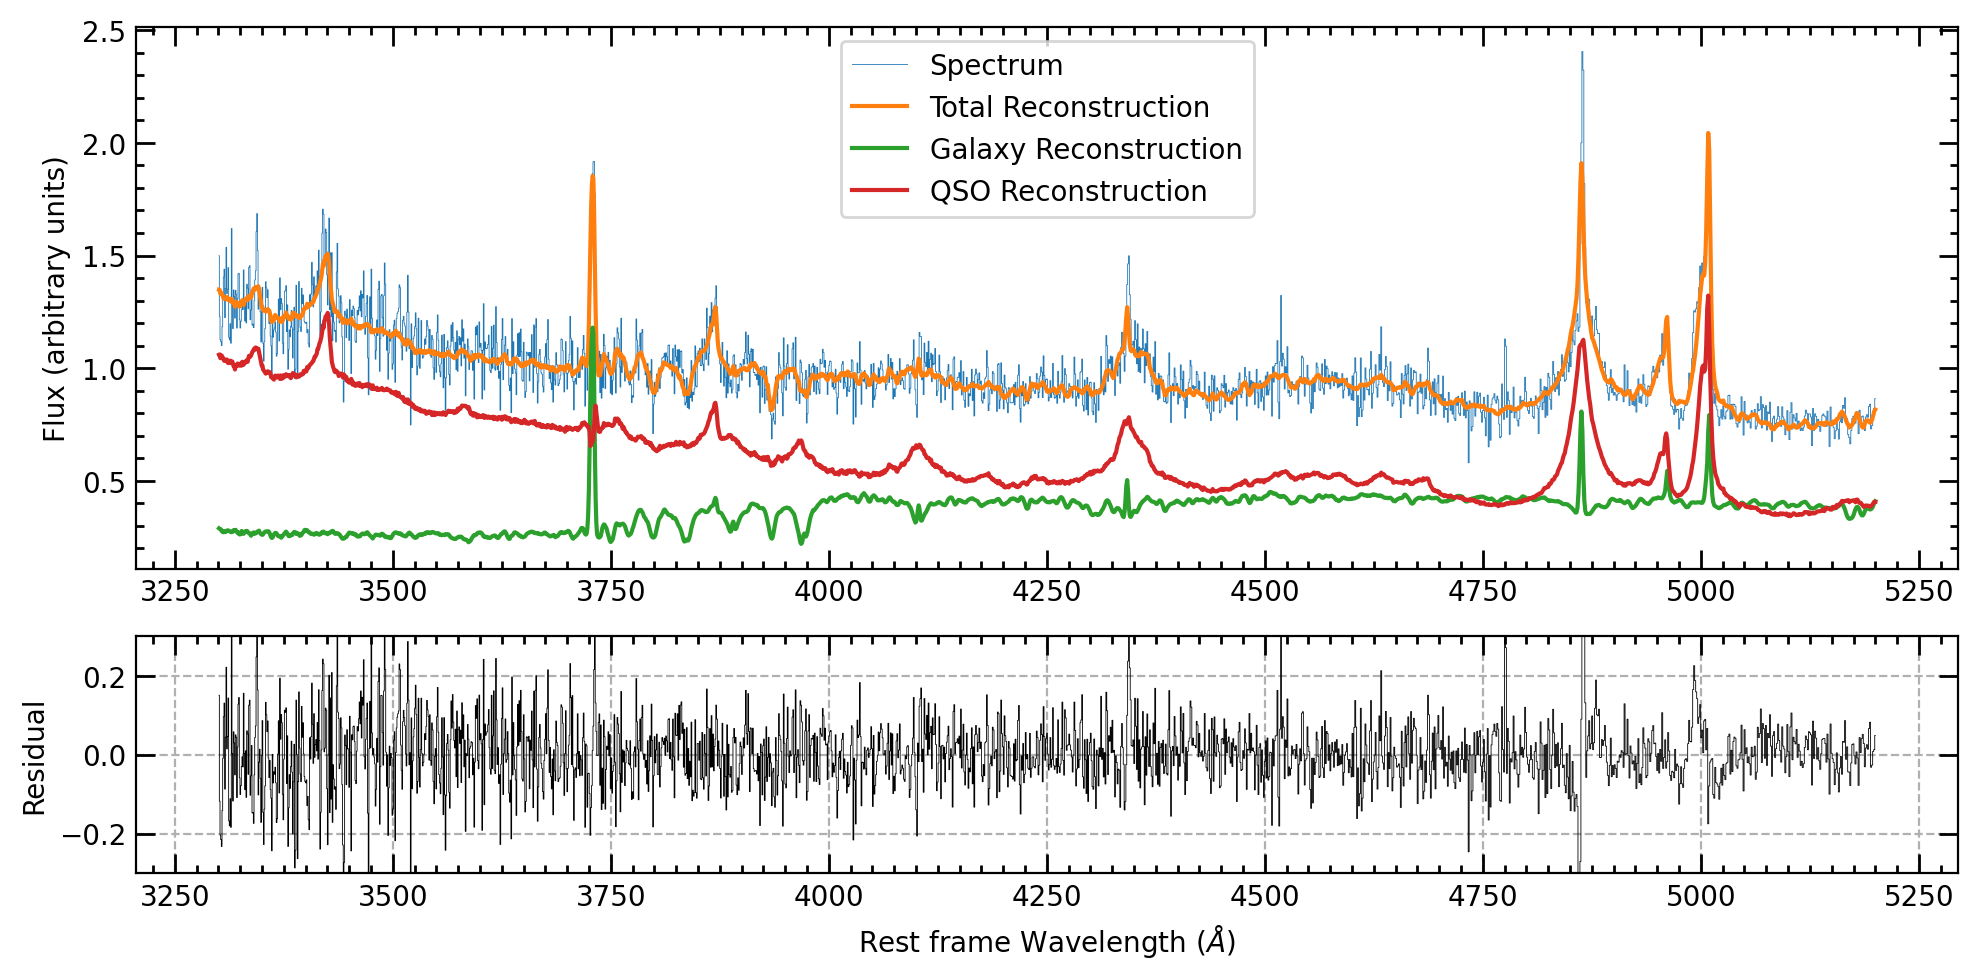

In [35]:
obj = mfica(wl, fl, err) # Loads an instance of MFICA
obj.fit_comps() # Fits the components

# Plot the best-fitting model
obj.plot_model()

We can now infer its host galaxy SFH using the component fractions.

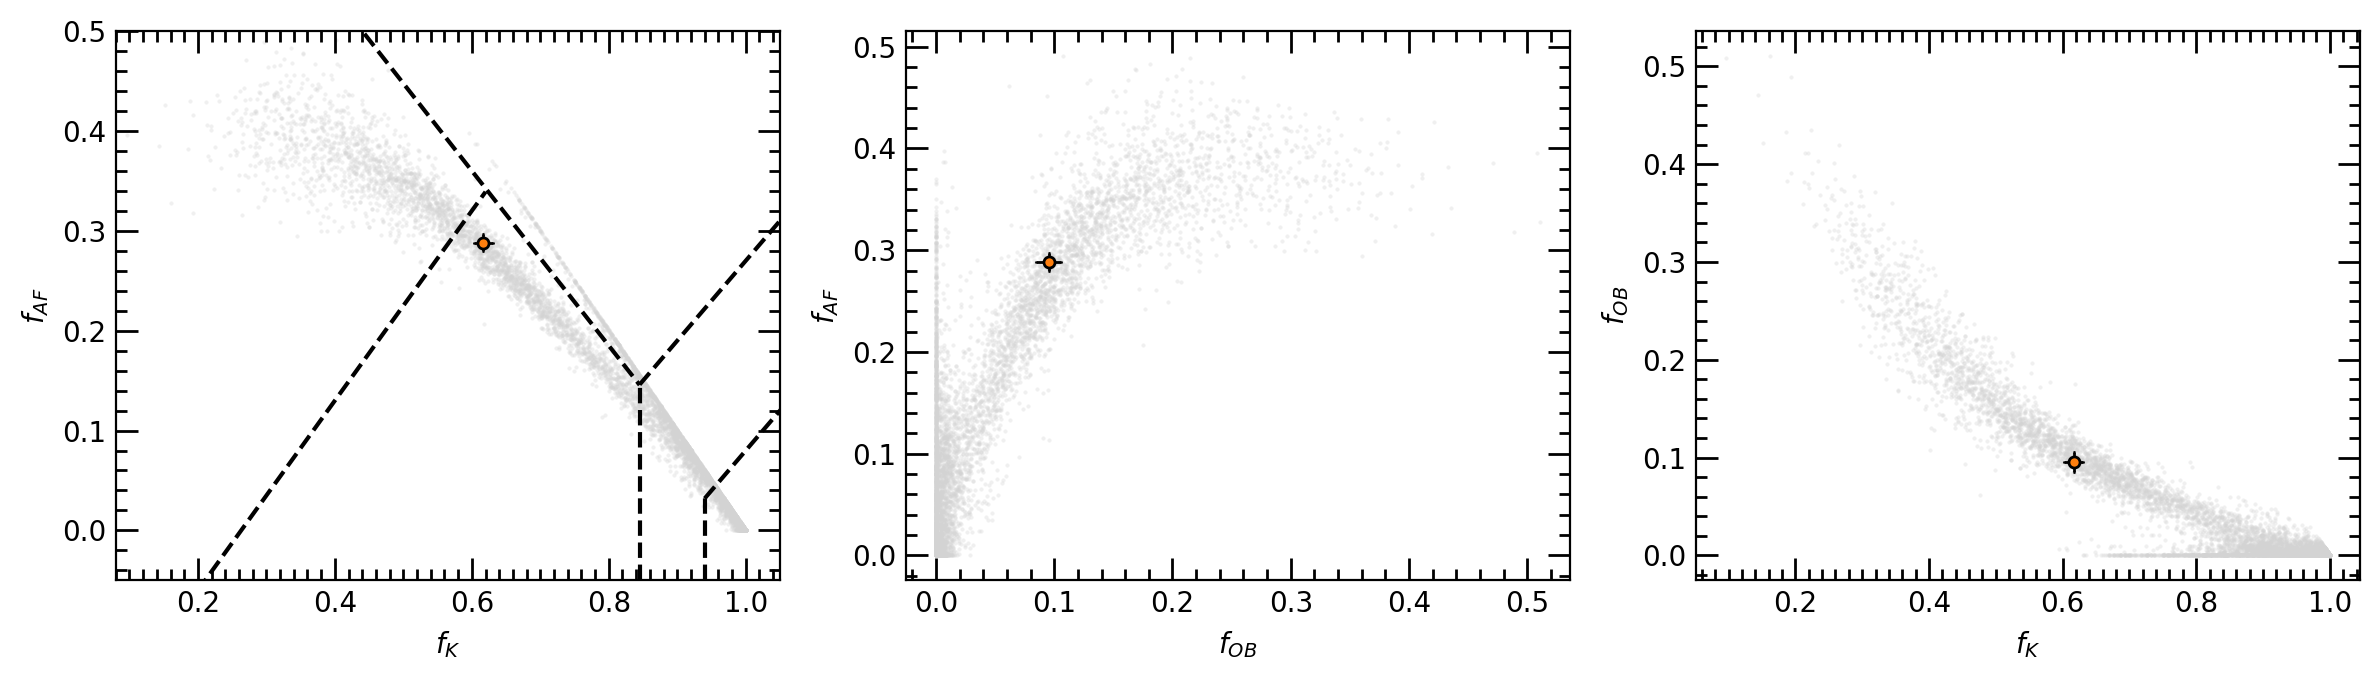

In [36]:
obj.plot_comp_frac()

This quasar host galaxy is a star-forming galaxy. 

NOTE: It is recommended to infer host galaxy properties only if the mean ratio of host galaxy to total spectrum flux is greater than 10%.